# GEOG 3155 6155 Lab 08



# Introduction

While machine learning methods have been frequently used with spatial data, there is a growing awareness of how the characteristics of these data may cause some issues. In this lab, we'll look at how more robust methods of evaluating machine learning models with spatial data, and at some approaches that can incorporate location and improve predictions.

We'll use a couple of datasets to illustrate these methods:

-   *lsl.csv*: Location of landslide events in southern Ecuador
-   *ta.tif*: A raster file with environmental predictors
-   *data_atlantic_1998_2012.csv*: A dataset of cancer rates for counties in Atlantic states
-   *COUNTY_ATLANTIC.zip*: a shapefile for the Atlantic States


## Objectives

-   Understand how to use different cross-validation strategies for spatial data
-   Use a geographic random forest to explore spatial variations in model results
-   Incorporate location in machine learning models


You will need to make sure the following packages are installed on your computer (in addition to the packages we have used in previous labs). 

- **PyGRF**: functions for working with regular arrays like climate data. There is no version of this available currently for conda, but you should be able to install this with `pip install PyGRF. If you are unsure about this step, please ask me
- **geopandas**: package for working with geospatial data (`conda install geopandas`)
- **rasterio**: 

## Data processing

Let's start by by importing the modules we'll need for the class, then we'll go get the data

In [1]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

Let's load the landslide data first and take a look at the content:

In [2]:
lsl = pd.read_csv("./datafiles/lsl.csv")
lsl.head()

,x,y,lslpts,slope,cplan,cprof,elev,log10_carea
0,713887.726935,9.558537e+06,False,33.751854,0.023180,0.003193,2422.810,2.784319
1,712787.726935,9.558917e+06,False,39.408215,-0.038639,-0.017188,2051.771,4.146013
2,713407.726935,9.560307e+06,False,37.454094,-0.013329,0.009671,1957.832,3.643556
3,714887.726935,9.560237e+06,False,31.496073,0.040931,0.005889,1968.621,2.268703
4,715247.726935,9.557117e+06,False,44.074558,0.009687,0.005150,3007.774,3.003426


The first two columns show the easting and northing. The third indicates whether or not a landslide had occurred at that location (the target) and the remaining columns are features to be used in the model. See the appendix for more detail on these. Let's convert this to a geopandas dataframe so we can map out the landslide points


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

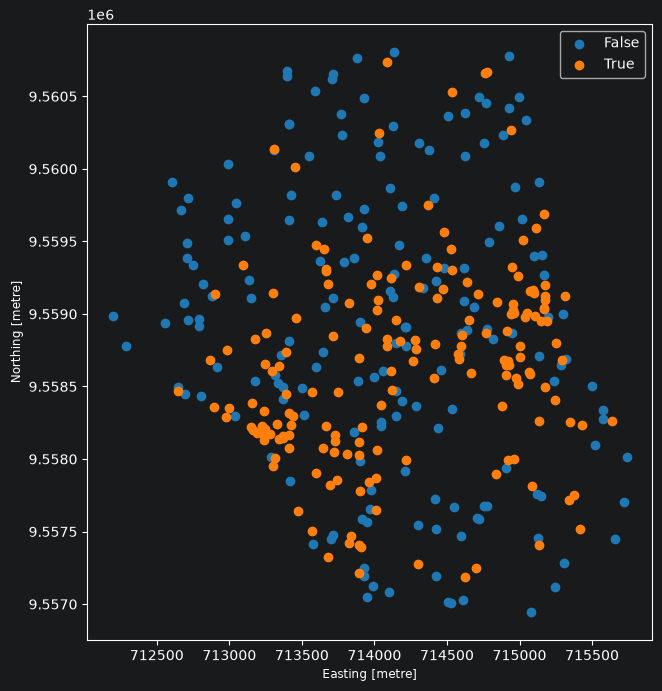

In [3]:
lsl_gpd = gpd.GeoDataFrame(lsl, 
                           geometry=gpd.points_from_xy(lsl['x'], lsl['y']), 
                           crs=32717)
lsl_gpd.plot('lslpts', legend=True, figsize=(8, 8))

Next let's load some environmental data to make predictions. This is in a multi-layer GeoTIFF file, and we can load it using the **rasterio** package. We start by opening a connection to the file, which lets us look at certain details (size, CRS, number of bands)


In [4]:
import rasterio
from rasterio.plot import show

#with rasterio.open('./datafiles/ta.tif') as dataset:
#    data = dataset.read(1) # Reads the first band
env_dataset = rasterio.open("./datafiles/ta.tif")
print(env_dataset.crs)
print(env_dataset.shape)

EPSG:32717
(415, 383)


Now we can read an individual layer and plot. Note that the band numbering starts at 1, so this is the first band (the `slope` values)

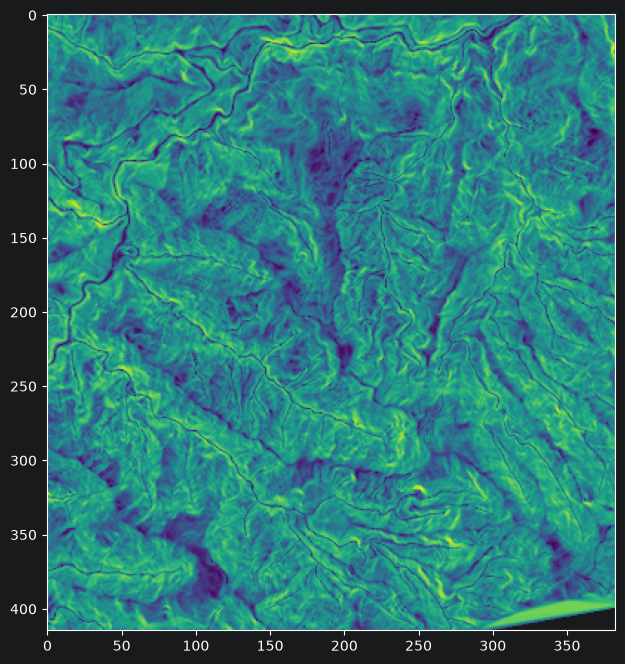

<Axes: >

In [5]:
arr1 = env_dataset.read(1)
plt.subplots(figsize=(8,8))
show(arr1)

In order to be able to use these values in model predictions, we need to convert to a 2D array, where every row is a single pixel and every column the corresponding value for one of the bands. As we know in this case that the order of the bands follows the same order as the columns in the `lsl` dataframe, we can do this with a simple reshape. First read all the data:

In [6]:
with rasterio.open('./datafiles/ta.tif') as src:
        env = src.read()
        metadata = src.meta

Now reshape. We first extract the dimensions of the the original image - we'll need these later to turn our predictions back into a raster format

In [7]:
# Reshape the image data
num_bands, height, width = env.shape
env_reshaped = env.reshape(num_bands, -1).T

The last thing we need to do before modeling is setup the array of features (`X`) and target (`y`). All the values are numeric and relatively normally distributed, so we don't need any other processing. 

In [8]:
lsl.columns

Index(['x', 'y', 'lslpts', 'slope', 'cplan', 'cprof', 'elev', 'log10_carea'], dtype='str')

In [9]:
all_vars = ['slope', 'cplan', 'cprof', 'elev', 'log10_carea']
X = lsl[all_vars]
y = lsl['lslpts']

# Spatial cross-validation

## Baseline model

First, let's build a simple model using a classic train/test split (80/20) and evaluate it. First create the training/test split. Note that the data is well balanced (equal numbers of 1's and 0's) so we don't need to worry about stratifying the sample:


In [10]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, shuffle=True)

Now import a random forest classifier and train it. 

In [11]:
from sklearn.ensemble import RandomForestClassifier
lsl_rf = RandomForestClassifier()

lsl_rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

And get the AUC score as a baseline measure of model performance

In [12]:
from sklearn.metrics import roc_auc_score

y_test_pred = lsl_rf.predict_proba(X_test)

lsl_auc = roc_auc_score(y_test, y_test_pred[:,1])
print(f'ROC AUC: {np.round(lsl_auc, 4)}')

ROC AUC: 0.826


We get an AUC of around 0.85, which indicates a pretty good model. We'll dig into this more below.

Next, let's predict landslide susceptibility for the study region using the raster images we loaded above and extracted to the array `env_reshaped`. We then use the saved dimensions of the original image to convert this back to an array and plot

C:\Users\u6025895\.virtualenvs\.venv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


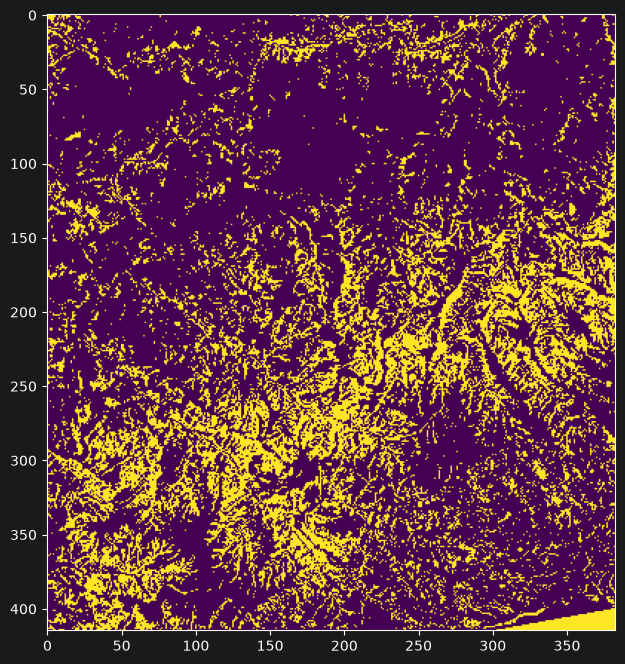

In [13]:
predictions_reshaped = lsl_rf.predict(env_reshaped)
    
predictions = predictions_reshaped.reshape(height, width)

plt.subplots(figsize=(8,8))
plt.imshow(predictions)


The map shows the distribution of predicted landslides (yellow) and non-landslides (purple). A more useful result would be to plot the probability and use tbhis as a measure of landslide susceptibility, which clearly shows a highly susceptible band runnning east-west in the lower half of the study area

C:\Users\u6025895\.virtualenvs\.venv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


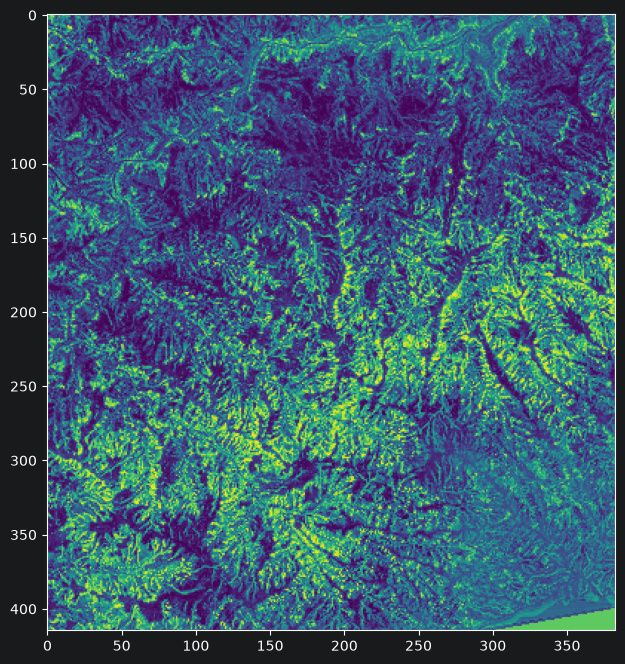

In [14]:
predictions_reshaped = lsl_rf.predict_proba(env_reshaped)
predictions = predictions_reshaped[:,1].reshape(height, width)

plt.subplots(figsize=(8,8))
plt.imshow(predictions)

We can save this results to a new GeoTiff to be able to import into a GIS platform or other software. This is a three step process where we first make a copy of the metadata from the original image, update the number of bands to 1 (as we only have a single layer to export) and write to the new file

In [15]:
# Update metadata for the new GeoTIFF
metadata_pred = metadata
metadata_pred['count'] = 1  # Single-band output
    
# Save the prediction as a new GeoTIFF
with rasterio.open('./datafiles/predicted_lsl.tif', 'w', **metadata_pred) as dst:
        dst.write(predictions, 1)

## Spatial cross-validation

Now let's dig a little further into the cross-validation of this model. The AUC value we got above is from a single hold-out, ignoring the spatial distribution of the observations.

First, let's re-run this as a 5-fold cross-validation to get a more robust estimate. For this we:

-   Set up a $k$-fold cross-validation strategy
-   Instantiate a random forest (we could simply reuse the code above, but adding this here helps clarify what is going on)
-   Run the cross-validation and check the results

In [16]:
from sklearn.model_selection import KFold, cross_val_score

n_splits=5
cv = KFold(n_splits=n_splits, shuffle=True, random_state=42)

In [17]:
lsl_rf = RandomForestClassifier()
scores = cross_val_score(lsl_rf, X, y, cv=cv, scoring = 'roc_auc')
print(f"AUC mean: {np.round(np.mean(scores), 3)}; AUC sd {np.round(np.std(scores), 3)}")

AUC mean: 0.847; AUC sd 0.015


And we get a similar, but more robust AUC estimate. However, we still haven't accounted for the spatial dependency in the data. This means that the value we have is somewhat reliant on the spatial correlation between the training and test set, as the observations are mixed. This means that our AUC value is really telling us about how well the model predicts *within* existing observations, in other words, how well it can interpolate.

To illustrate this, let's extract the fold IDs (i.e. which training fold each observation belongs to) to show how these are distributed

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

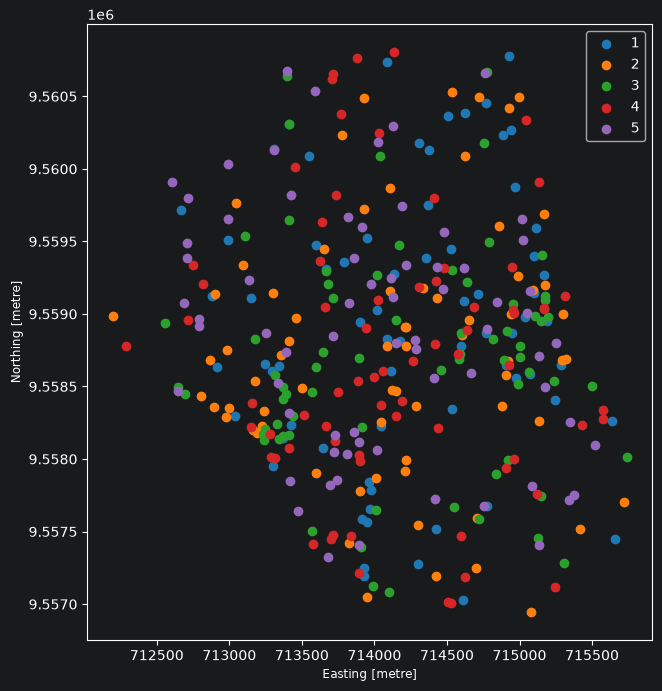

In [18]:
lsl_gpd['foldID'] = '0'

i = 1
for split in cv.split(X):
    #print(split)
    lsl_gpd.loc[split[1],'foldID'] = str(i)
    i += 1

lsl_gpd.plot('foldID', legend=True, figsize=(8,8))

A different test is how well our model would work in an area where we know the features, but we don't have any observations of landslides (or non-landslides). This will tell us how well the model works at predicting *outside* existing observations, or how well it can extrapolate. To test this, we need to use a spatial sampling method that will divide the data into contiguous training and testing regions. In a spatial $k$-fold, we divide the data into $k$ regions, set one as testing and the others as training, fit and evaluate a model and repeat. 

There's a number of ways to do this. We'll use a simple clustering algorithm based on the coordinates to cluster observations into contiguous regions. We'll do this by hand here, but if you are interested in exploring this further, see https://github.com/SamComber/spacv for more options)

We're going to explore cluster analysis in a few weeks, so I won't comment the code below. We'll just run it and plot the results

In [19]:
from sklearn.cluster import KMeans

crds = lsl[['x','y']]
kmeans = KMeans(n_clusters=n_splits, random_state=42, n_init='auto')
clusters = kmeans.fit_predict(crds)

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

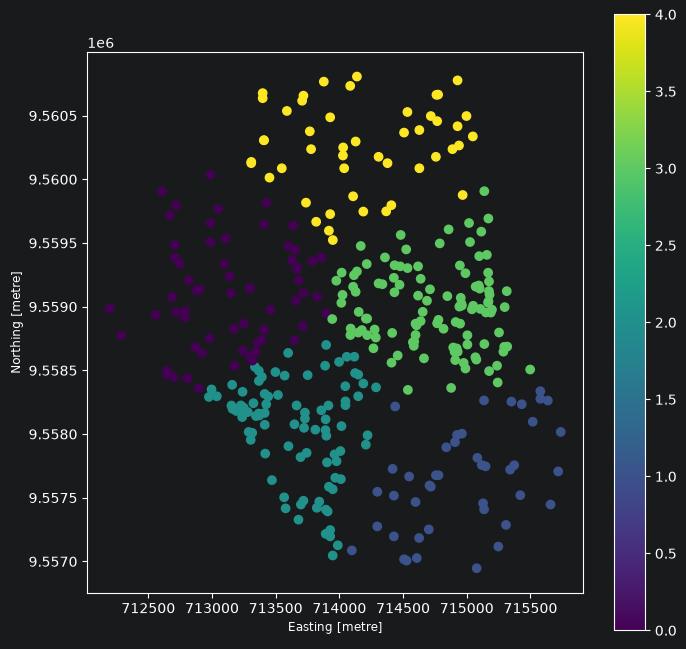

In [20]:
lsl_gpd['foldID'] = clusters
lsl_gpd.plot('foldID', legend=True, figsize=(8,8))

We can now use thes cluster assignments to create a new set of folds for cross-validation using `GroupKFold`. 

In [21]:
from sklearn.model_selection import GroupKFold
group_kfold = GroupKFold(n_splits=n_splits)

# Generator for the train/test indices
cv_sp = group_kfold.split(X, y, clusters)

And re-run the 5-fold crossvalidation with this:

In [22]:
scores = cross_val_score(lsl_rf, X, y, cv=cv_sp, scoring = 'roc_auc')
print(f"AUC mean: {np.round(np.mean(scores), 3)}; AUC sd {np.round(np.std(scores), 3)}")

AUC mean: 0.744; AUC sd 0.067


You should see here that the AUC decreases substantially, indicating less predictive power when extrapolating.


# Using location in machine learning

We'll now move on to exploring the use of location in machine learning. We'll look at this in three ways

-   Geographical random forest (GRF)
-   Using coordinates as features
-   Spatial basis functions

We'll also use a different data set here, with a continuous outcome, as the current GRF implementation does not work (well) with with binary outcomes.

The file *data_atlantic_1998_2012.csv* contains information on cancer rates from around 660 counties in the eastern part of the US. Let's load that here as well as a shapefile containing the county polygons:

In [23]:
cancer = pd.read_csv("./datafiles/data_atlantic_1998_2012.csv")
cancer.head()

,FIPS,x,y,Cancer,Poverty,Smoking,PM25,NO2,SO2
0,13111,1056523.936,1376613.190,72,15.920000,27.933333,11.755333,0.977667,0.064185
1,42115,1653442.064,2267301.476,59,12.220000,26.966667,9.026000,1.499933,0.033211
2,42075,1633708.275,2096683.059,61,8.986667,25.273333,11.963333,3.616467,0.120281
3,51683,1584048.852,1901443.401,62,7.860000,22.900000,12.731333,3.621933,0.118371
4,36057,1735811.102,2409536.493,59,14.746667,27.180000,8.302000,1.632733,0.006404


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

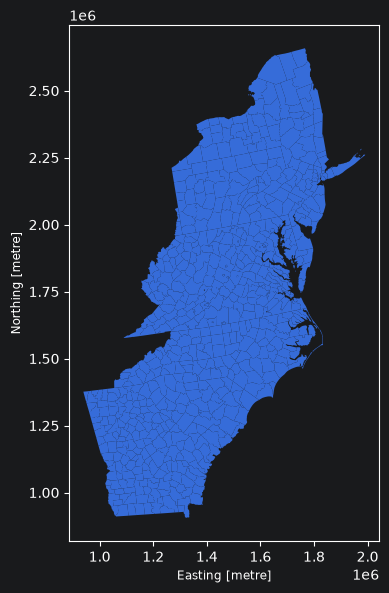

In [25]:
atl = gpd.read_file("./datafiles/COUNTY_ATLANTIC/COUNTY_ATLANTIC.shp")
atl.plot(figsize=(4,8))

Both the shapefile and the cancer data have the county FIPS code, so we can use this to merge the two datasets together, which allows us to map out the cancer rates, showing high rates in the south and western part of the region:

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

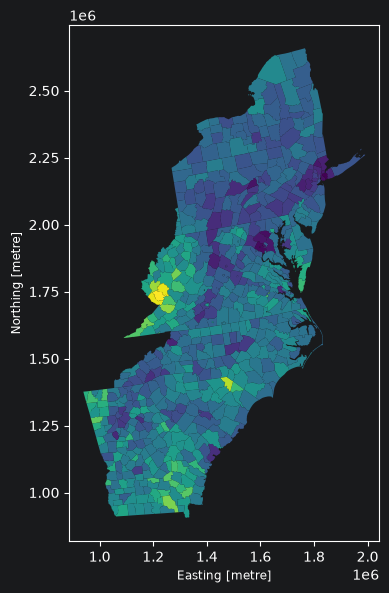

In [26]:
atl_cancer = atl.merge(cancer, on="FIPS")
atl_cancer.plot("Cancer", figsize=(4,8))

## Geographical random forest

Let's start this section by building a GRF with these data. To keep things simple here and below, we'll just use the pollutant variables as features (`PM25`, `NO2` and `SO2`). The GRF function uses a similar syntax to **scikit-learn** models, but needs a second dataframe with the coordinates of each spatial location. We'll extract this from the `geopandas` object by finding the centroids, and then the coordinates of these. We'll also make the usually `X` and `y` arrays for features and targets

In [27]:
atl_crds = atl_cancer.centroid.get_coordinates()

all_vars = ["PM25","NO2","SO2"]
X = cancer[all_vars]
y = cancer['Cancer']

Now we can fit the model. We won't try and tune this here, but instead run it with an adaptive kernel that uses the 50 closest locations to build each model in a moving window (you might want to try playing with the `band_width` argument to see how this affects the results). Note the other arguments:

- `train_weighted`: weight training samples by distance to current location
- `predict_weighted`: Use all local models within `band_width` to make predictions at new location or the closest
- `bootstrap`: bootstrap resample the training data

In [29]:
from PyGRF import PyGRF
grf = PyGRF.PyGRFBuilder(n_estimators=100, max_features=1, 
                         band_width=50, kernel="adaptive",
                         train_weighted=True, predict_weighted=True, 
                         bootstrap=True, random_state=42)

grf.fit(X,y, atl_crds)

C:\Users\u6025895\.virtualenvs\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


(array([76.48837209, 65.03448276, 68.55813953, 63.71794872, 66.6       ,
        69.78571429, 73.23529412, 69.44117647, 73.61111111, 71.975     ,
        68.11111111, 75.29411765, 58.2       , 66.19512195, 71.06451613,
        81.0625    , 64.51111111, 63.69047619, 67.23404255, 71.81818182,
        74.93939394, 62.97435897, 70.79487179, 54.17391304, 81.22857143,
        84.7       , 81.34883721, 69.05714286, 68.5       , 67.71052632,
        76.26315789, 83.35135135, 74.20930233, 68.33333333, 72.18421053,
        81.55      , 50.        , 76.775     , 49.18421053, 67.63043478,
        63.125     , 69.2       , 68.16666667, 64.96875   , 69.06060606,
        66.1875    , 57.85714286, 68.59459459, 72.6097561 , 80.32258065,
        78.69230769, 85.375     , 75.63888889, 72.51612903, 70.25      ,
        70.5       , 71.85      , 76.59459459, 80.57575758, 70.60526316,
        75.1       , 82.25714286, 66.73076923, 65.85365854, 64.5       ,
        63.        , 72.76315789, 71.73809524, 70.1

The function will give you quite a lot of output. The routine starts by fitting a global model (i.e. with all the observations) and then fits local models to each observation using the kernel we defined in the function. 

More usefully, we can start to visualize the results. First we'll explore the importance of the three features we used in the model. As a remidner, this is a measure of the loss of predictive power when one of the variables is randomly shuffled. Let's start by plotting the importance scores for the global model:

In [30]:
grf.global_model.feature_importances_

array([0.3053183 , 0.38632595, 0.30835574])

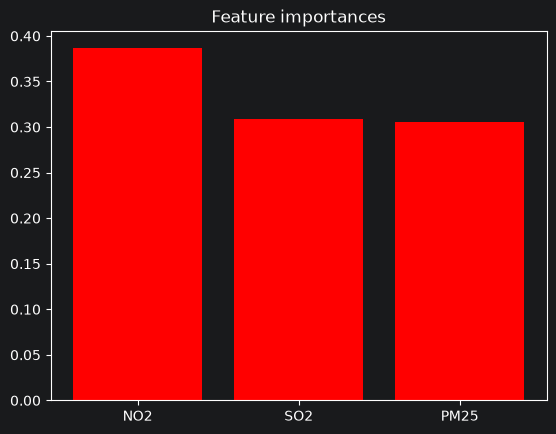

In [31]:
importances = grf.global_model.feature_importances_
indices = np.argsort(importances)[::-1]

# Plot the impurity-based feature importances of the forest
plt.figure()
plt.title("Feature importances")
plt.bar(np.array(all_vars)[indices], 
        importances[indices],
        color="r", align="center")
plt.show()

Next, let's get the local importance scores. In the model output, there is a method called `get_local_feature_importance` which (unsurprisingly) extracts the importance scores for each model (for each location). A second method (`get_local_R2`) gets goodness of fit scores for each location and we'll use this to visualize variations in the R2:

In [32]:
loc_vip = grf.get_local_feature_importance()

Text(0.5, 1.0, 'PM2.5')




In [33]:
atl_cancer['PM25_vip'] = loc_vip['PM25']
atl_cancer.plot('PM25_vip', legend=True, figsize=(6,10), cmap='OrRd')
plt.title("PM2.5")

Text(0.5, 1.0, 'NO2')




In [34]:
atl_cancer['NO2_vip'] = loc_vip['NO2']
atl_cancer.plot('NO2_vip', legend=True, figsize=(6,10), cmap='OrRd')
plt.title("NO2")

Text(0.5, 1.0, 'SO2')




In [35]:
atl_cancer['SO2_vip'] = loc_vip['SO2']
atl_cancer.plot('SO2_vip', legend=True, figsize=(6,10), cmap='OrRd')
plt.title("SO2")

Text(0.5, 1.0, 'Local R2')




In [64]:
loc_r2 = grf.get_local_R2()
atl_cancer['loc_r2'] = loc_r2['local R2']

atl_cancer.plot('loc_r2', legend=True, figsize=(6,10), cmap='OrRd')
plt.title("Local R2")

A few things to note from these maps:

-   The local R2 values vary a lot (with some regions that have negative values). This can be interpreted as a map of where the model is doing a reasonable job (green) and where it fails (red). The low values indicate that other variables may be important in producing this model
-   The importance scores for the three features largely follow the same pattern (high importance around metropolitan centers, low elsewhere). This is not too surprising as pollutant values tend to correlate pretty strongly.

## Using coordinates as features

Next, we'll explore the use of coordinates as features. Conceptually, we are trying to improve the model outcome by incorporating some measure of spatial dependency or autocorrelation between locations. This helps to address models that tend to over- or under-estimate systematically in space. To illustrate this point, we'll first make a random forest model using all the data:


In [37]:
from sklearn.ensemble import RandomForestRegressor

all_vars = ["PM25","NO2","SO2"]
X = cancer[all_vars]
y = cancer['Cancer']

cancer_rf = RandomForestRegressor()
cancer_rf.fit(X,y)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the numb

Now predict and merge into the `geopandas` object:

In [38]:
atl_cancer['yhat'] = cancer_rf.predict(X)

Calculate the error as prediction - observation and plot:

Text(0.5, 1.0, 'RF errors')

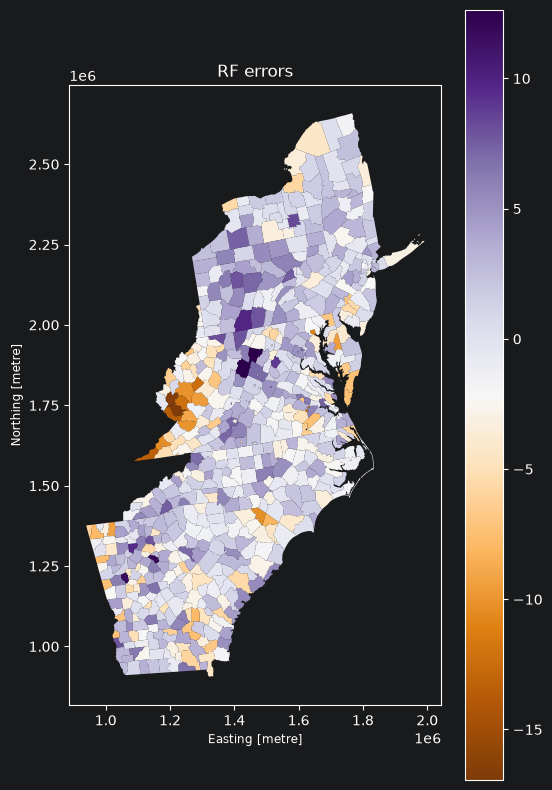

In [39]:
atl_cancer['error'] = atl_cancer['yhat'] - atl_cancer['Cancer']

atl_cancer.plot('error', legend=True, figsize=(6,10), cmap="PuOr")
plt.title("RF errors")

And these results show that systematic error in the model (note the patches of negative values and positive values). Before including the coordinates in a model, let's run a 5-fold cross-validation on this model to get a reference RMSE and $R^2$.

In [40]:
n_splits=5
cv = KFold(n_splits=n_splits, shuffle=True, random_state=42)

scores = cross_val_score(cancer_rf, X, y, cv=cv, scoring = 'neg_root_mean_squared_error')
print(f"RMSE mean: {np.round(np.mean(-scores), 3)}; RMSE sd {np.round(np.std(-scores), 3)}")

RMSE mean: 10.949; RMSE sd 0.424


Now let's re-run this with coordinates included (these are in the `x` and `y` columns or we could use the centroid coordinates we extracted earlier):

In [41]:
all_vars = ["PM25","NO2","SO2","x","y"]
X = cancer[all_vars]
y = cancer['Cancer']

scores = cross_val_score(cancer_rf, X, y, cv=cv, scoring = 'neg_root_mean_squared_error')
print(f"RMSE mean: {np.round(np.mean(-scores), 3)}; RMSE sd {np.round(np.std(-scores), 3)}")

RMSE mean: 8.871; RMSE sd 0.475


And we get a pretty substantial improvement in model performance, with around a 2 point drop in RMSE.


## Spatial basis functions

As a final step, we'll re-fit this model using spatial basis functions to represent location. As a reminder, these functions are designed to encode relative location (i.e. the proximity of each observation to the others) in a way that maximizes the signal-to-noise ratio in a memory efficient manner. These are best suited for large spatial and spatio-temporal datasets; we'll use them here more as a demonstration of how to create and use these.

As this is a fairly new technique, there are no existing functions to get basis values for machine learning (that I'm aware of). The code below will build two sets of basis functions, one at low resolution and one at high. If you're interested in the details of how this works, please see the appendix below.

First convert coordinates to a numpy array and and create function to get the basis weights

In [42]:
## Get bounding box
atl_bbox = atl_cancer.total_bounds

## Get coordinates
atl_crds = atl_crds.to_numpy()

## Bisquare basis function
def bisquare_basis(d, sigma):
    if (d <= sigma):
        w = (1 - (d / sigma)**2)**2
    else:
        w = 0
    return w

#### Level 1 (low-resolution)

In [43]:
## Knots
nx = 3
ny = 5

xgrid = np.linspace(atl_bbox[0], atl_bbox[2], nx)
ygrid = np.linspace(atl_bbox[1], atl_bbox[3], ny)

## Knot grid
knots_x, knots_y = np.meshgrid(xgrid, ygrid)
knots = np.stack((knots_x, knots_y), axis=-1)
knots = knots.reshape(-1,2)

## Basois function radius (m)
sigma = 5e5

## Number of obs and knots for loop
nobs = atl_crds.shape[0]
nknots = knots.shape[0]

phi1 = np.zeros((nobs, nknots))

for i in range(nobs):
    for j in range(nknots):
        d = np.linalg.norm(atl_crds[i,:] - knots[j,:])
        #print(i,j, d)
        phi1[i,j] = bisquare_basis(d,sigma)

#### Level 2 (high-resolution)

In [44]:
## Knots
nx = 3*3
ny = 5*3

xgrid = np.linspace(atl_bbox[0], atl_bbox[2], nx)
ygrid = np.linspace(atl_bbox[1], atl_bbox[3], ny)

## Knot grid
knots_x, knots_y = np.meshgrid(xgrid, ygrid)
knots = np.stack((knots_x, knots_y), axis=-1)
knots = knots.reshape(-1,2)

## Basis function radius (m)
sigma = 2e5

## Number of obs and knots for loop
nobs = atl_crds.shape[0]
nknots = knots.shape[0]

phi2 = np.zeros((nobs, nknots))

for i in range(nobs):
    for j in range(nknots):
        d = np.linalg.norm(atl_crds[i,:] - knots[j,:])
        #print(i,j, d)
        phi2[i,j] = bisquare_basis(d,sigma)

We now have the basis functions for the two levels (`phi1` and `phi2`). We'll now:

- merge these into a single array
- remove any functions with no non-zero values (as these are two far away from any data point)
- merge the remaining set into out feature data (`X`)

In [45]:
phi = np.hstack((phi1,phi2))
print(f"Phi          : {phi.shape}")

idx_zero = np.array([], dtype=int)
for i in range(phi.shape[1]):
    if sum(phi[:,i]!=0)==0:
        idx_zero = np.append(idx_zero,int(i))

phi = np.delete(phi,idx_zero,1)
print(f"Phi (reduced): {phi.shape}")

Phi          : (666, 150)
Phi (reduced): (666, 112)


In [46]:
all_vars = ["PM25","NO2","SO2"]
X = cancer[all_vars]

# Convert NumPy array to DataFrame
phi_df = pd.DataFrame(phi)
phi_df.columns = ["b"+str(i) for i in range(0, phi.shape[1])]

X = pd.concat([X, phi_df], axis=1)


Now we have this merged, we can build and evaluate a random forest model that includes these basis functions. Note that we set the number of trees and features to be used to fairly high values as we now have a much bigger dataset

In [47]:
cancer_rf = RandomForestRegressor(n_estimators=2000, max_features=20, n_jobs=-1)

n_splits=5
cv = KFold(n_splits=n_splits, shuffle=True, random_state=42)

scores = cross_val_score(cancer_rf, X, y, cv=cv, scoring = 'neg_root_mean_squared_error')
print(f"RMSE mean: {np.round(np.mean(-scores), 3)}; RMSE sd {np.round(np.std(-scores), 3)}")

RMSE mean: 8.429; RMSE sd 0.367


And we get another small improvement in the model. Note that we have not tuned any of these models (or the basis functions), and it's is possible that better performance could be achieved in practice.

## Exercise

In the cancer dataset, there are two possible predictor variables that we did not use above (poverty rates `Poverty` and smoking rates `Smoking`). For the exercise, you will need run a new analysis that includes these. There are three options given below; students in GEOG 3155 will need to do one of these, students in GEOG 6155 will need to do two.

1.  Use the cancer dataset to carry out a non-spatial and spatial cross-validation, following the example above. This will be a regression task, and you should include all the possible predictors (poverty, smoking and air pollutants). You can use a random forest, or any of the other algorithms we have looked at so far. Report the RMSE and $R^2$ for both cross-validation methods, and write a short statement that explains in simple terms what these mean (1-2 sentences)
2.  Make a new geographical random forest model that includes the variables mentioned above. Your answer should include a) a variable importance plot based on the global model; b) maps of the importance scores for all variables and the local $R^2$; c) a short description (2-4 sentences) of the spatial patterns you observe
3.  Make a new model with spatial basis functions that includes the variables mentioned above. You should try at least two different basis functions setups (I'd recommend that at least one uses the irregular basis functions described in the section above). Your answer should include a) a figure showing the distribution of the basis functions you used; b) cross-validated RMSE and $R^2$ values; c) a short statement as to whether the basis functions have improved the model (1-2 sentences)

Use a new notebook to record your answers and output. These should be submitted to Canvas. Please use the following naming convention: `Lab08_lastname.ipynb`.

# Appendix 1: Datafiles

## *lsl.csv*

-   `x`: easting (m)
-   `y`: northing (m)
-   `lslpts`: presence or absence of landslide (`[0,1]`)
-   `slope`: slope angle (degrees)
-   `cplan`: plan curvature (rad m−1) expressing the convergence or divergence of a slope and thus water flow
-   `cprof`: profile curvature (rad m-1) as a measure of flow acceleration, also known as downslope change in slope angle
-   `elev`: elevation (m a.s.l.) as the representation of different altitudinal zones of vegetation and precipitation in the study area
-   `log10_carea`: the decadic logarithm of the catchment area (log10 m2) representing the amount of water flowing toward a location

## *ta.tif*

Raster dataset with same predictor variables as *lsl.csv*

## *data_atlantic_1998_2012.csv*

- `FIPS`: County FIPS code
- `x`: Easting (m)
- `y`: Northing (m)
- `Cancer`: Cancer mortality rate / 100,000
- `Poverty`: Poverty rate (% below poverty level)
- `Smoking`: Smoking rate (%)
- `PM25`: Annual mean PM2.5 concentration
- `NO2`: Annual mean NO2 concentration
- `SO2`: Annual mean SO2 concentration

# Appendix 2: Making spatial basis functions

As this is a fairly new technique, there are no existing functions to get basis values for machine learning (that I'm aware of). So in this appendix, we'll walk through the code used above to try and explain a little more about what is going on, and so hopefully, you would be able to adapt this to your own data. Getting basis weights for observations needs a few steps:

- Define the *levels*: the number of basis functions at different resolutions
- Define the *knots*: the center points for each basis function (we'll define the number of these in `x` and `y` for each resolution)
- Define *basis functions*: a function that describes the change in weights with distance to the knots. This requires a parameter `sigma` which defines the radius of influence of each knot
- Calculate the *distance* between each observation and the set of knots and store as an array

We'll walk through the steps individual for the first level here:

### Define levels

This is a pretty simple step. For this problem we'll use two levels (low and high resolution)

In [48]:
nlevels = 2
## Set current level
level = 1

### Define the knots

We'll use a grid of 3 knots (east-west) and 5 knots (north-south for this first level). As a hint here, we want the knots to have roughly the same spacing in `x` and `y`

In [49]:
nx = 3
ny = 5

Now we need to find the coordinates for each of these. The easiest way to do this is to place the first and last knot at the boundaries of the region and then position any remaining knots evenly between these. An alternative would be to specify the resolution directly (e.g. every 100km, etc). We'll use the first method here, so we'll need the bounding box for the data:

In [50]:
atl_bbox = atl_cancer.total_bounds
print(atl_bbox)

[ 939223.08173344  905588.42555705 1991063.57131896 2658558.08278061]


Now let's set the range in x and y, and then set regular points between these bounds

In [51]:
xgrid = np.linspace(atl_bbox[0], atl_bbox[2], nx)
print(xgrid)

ygrid = np.linspace(atl_bbox[1], atl_bbox[3], ny)
print(ygrid)

[ 939223.08173344 1465143.3265262  1991063.57131896]
[ 905588.42555705 1343830.83986294 1782073.25416883 2220315.66847472
 2658558.08278061]


Now we can use **numpy**'s `meshgrid` function to turn these into the full set of knots

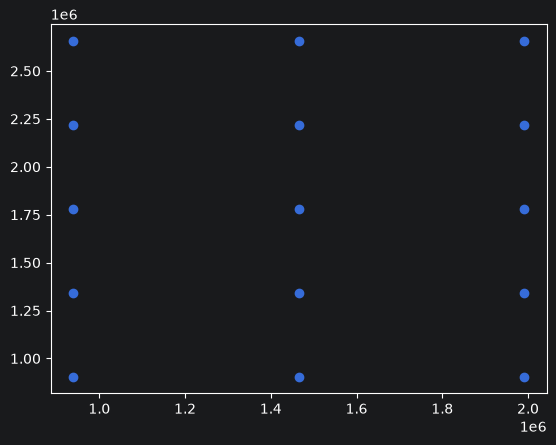

In [52]:
knots_x, knots_y = np.meshgrid(xgrid, ygrid)
knots = np.stack((knots_x, knots_y), axis=-1)
knots = knots.reshape(-1,2)
plt.plot(knots[:,0], knots[:,1], 'o')

### Define basis function

The next step is to define the basis function. This requires two things: the shape of the function and the size of the function. For the shape, we'll use the bisquare function, which gives a weight $w_i$ for any data point $i$ based on it's distance to the knot or center of a basis function. Other options include simple exponential decay or Gaussian functions, but the advantage of the bisquare is that the weight is set to zero if the distance is larger than the size ($\sigma$), which helps reduce amount of data we use. Otherwise the weight is calculated as follows:

$$
w_i = (1 - (d/\sigma)^2)^2
$$

To makes things easier, we'll set up a simple Python function to calculate this for us

In [53]:
## Bisquare basis function
def bisquare_basis(d, sigma):
    if (d <= sigma):
        w = (1 - (d / sigma)**2)**2
    else:
        w = 0
    return w

Now we can illustrate what this looks like as distance increases (this part is optional, it's just to visualize what the function looks like). We'll set a range of increases distances from 1 to 500000 (similar to the distance between knots) and plot the weights given a `sigma` value of 250000

Text(0, 0.5, 'Weight')

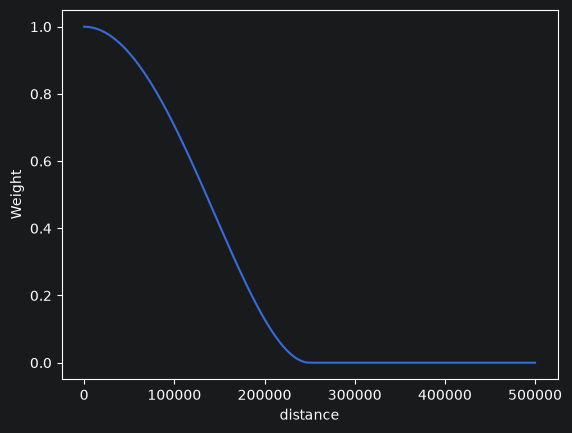

In [54]:
dist = np.linspace(0, 5e5, 250)
w = [bisquare_basis(d, sigma=250000) for d in dist]
plt.plot(dist, w)
plt.xlabel("distance")
plt.ylabel("Weight")

This shows a pretty rapid decline away from the center point. As a general rule, we want the basis functions to have a significant amount of overlap between centers, so a larger value will probbaly be useful for us:

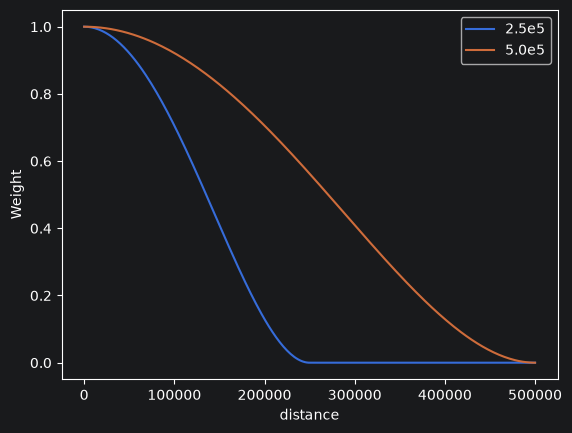

In [55]:
w2 = [bisquare_basis(d, sigma=500000) for d in dist]
plt.plot(dist, w, label="2.5e5")
plt.plot(dist, w2, label="5.0e5")
plt.xlabel("distance")
plt.ylabel("Weight")
plt.legend()

So we'll use a value of 5e5 (or 500,000) here

In [56]:
sigma = 5e5

### Calculate distance and weights between observations and knots

This is the final step. Here, we loop over every observation, and calculate the distance to every knot. We then use this value (`d`) in the bisquare function to get the weights, which we store in a matrix `phi`. First, get the number of observations and knots to define the loops

In [57]:
atl_crds = atl_cancer.centroid.get_coordinates()
atl_crds = atl_crds.to_numpy()

nobs = atl_crds.shape[0]
nknots = knots.shape[0]

Now run the loops. We'll use a numpy array (`phi1`) to store the weights

In [58]:
sigma = 5e5
phi1 = np.zeros((nobs, nknots))

for i in range(nobs):
    for j in range(nknots):
        d = np.linalg.norm(atl_crds[i,:] - knots[j,:])
        #print(i,j, d)
        phi1[i,j] = bisquare_basis(d,sigma)

And if we now take a look at this, you'll see weights attributed to each observation, linking them to the knots.

In [59]:
phi1[0,:]

array([0.00330679, 0.        , 0.        , 0.88484746, 0.10746729,
       0.        , 0.08258185, 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ])

We'll also calculate a second level of these with 3x the resolution, and a smaller value for sigma. Rather than going through the individual steps, I've just compiled all the code in this block

In [60]:
level = 2

nx = 3 * 3
ny = 5 * 3

xgrid = np.linspace(atl_bbox[0], atl_bbox[2], nx)
ygrid = np.linspace(atl_bbox[1], atl_bbox[3], ny)

knots_x, knots_y = np.meshgrid(xgrid, ygrid)
knots = np.stack((knots_x, knots_y), axis=-1)
knots = knots.reshape(-1,2)

nobs = atl_crds.shape[0]
nknots = knots.shape[0]

sigma = 2e5
phi2 = np.zeros((nobs, nknots))

for i in range(nobs):
    for j in range(nknots):
        d = np.linalg.norm(atl_crds[i,:] - knots[j,:])
        #print(i,j, d)
        phi2[i,j] = bisquare_basis(d,sigma)

We now have the basis functions for the two levels (`phi1` and `phi2`). We'll now:

- merge these into a single array
- remove any functions with no non-zero values (as these are two far away from any data point)
- merge the remaining set into out feature data (`X`) for use in machine learning

In [61]:
phi = np.hstack((phi1,phi2))
print(f"Phi          : {phi.shape}")

idx_zero = np.array([], dtype=int)
for i in range(phi.shape[1]):
    if sum(phi[:,i]!=0)==0:
        idx_zero = np.append(idx_zero,int(i))

phi = np.delete(phi,idx_zero,1)
print(f"Phi (reduced): {phi.shape}")

Phi          : (666, 150)
Phi (reduced): (666, 112)


In [62]:
all_vars = ["PM25","NO2","SO2"]
X = cancer[all_vars]

# Convert NumPy array to DataFrame
phi_df = pd.DataFrame(phi)
phi_df.columns = ["b"+str(i) for i in range(0, phi.shape[1])]

X = pd.concat([X, phi_df], axis=1)
